# Week 3, Task 5: leaderboard and difference maps

Scores every baseline's `ssp245` predictions the same way, puts them next to the published leaderboard, and shows
prediction − truth maps for each model and target.

Run with the **jcm** kernel. The metric code is in `metrics.py`, which every baseline notebook also uses.

**Adding a model:** its notebook saves `results/<model>_ssp245.nc` with variables `tas`, `diurnal_temperature_range`,
`pr`, `pr90`; dims `(time, lat, lon)` on the ClimateBench grid; years 2015–2100; precipitation in mm/day.
This notebook picks up every such file in `results/`.

## The metrics

All over 2080–2100, against the `ssp245` ensemble mean, with area weights ∝ cos(latitude):

- **Spatial NRMSE:** average each field over 2080–2100 first, then take the area-weighted RMSE between the two maps.
  Measures how well the *pattern* is captured.
- **Global NRMSE:** take the area-weighted global mean each year, then the RMSE between the two yearly series.
  Measures the *global trajectory*.
- Both are divided by |global mean of the truth over 2080–2100|, so targets with different units are comparable.
- **Total = spatial + 5 × global.** The global term is usually much smaller than the spatial one, and the global-mean
  trajectory is what many uses care about most, so it is weighted up.

DTR's global-mean change is close to zero, so dividing by it makes DTR's NRMSE large for every model.
Compare models within a target, not across targets.

In [1]:
import os
import sys
from glob import glob

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

REPO = os.path.abspath("..")          # this notebook lives in <repo>/notebooks
assert os.path.exists(f"{REPO}/metrics.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
from metrics import TARGETS, PERIOD, load_ssp245, global_mean, nrmse, variability_floor, variability_paper

DATA = os.path.expanduser("~/data/climatebench")
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"

STYLE = {"tas": ("tas", "K", "RdBu_r"),
         "diurnal_temperature_range": ("dtr", "K", "RdBu_r"),
         "pr": ("pr", "mm/day", "BrBG"),
         "pr90": ("pr90", "mm/day", "BrBG")}

members = load_ssp245(DATA)
truth = members.mean("member")

## Load every model's predictions

Each file is checked against the shared format before it is scored, so a wrong unit or grid fails loudly here
instead of quietly producing a bad score.

In [2]:
# file prefix -> display name, and the matching row of the published leaderboard
MODELS = {"pattern_scaling": ("Pattern scaling", "Pattern Scaling"),
          "gp": ("Gaussian process", "Gaussian Process"),
          "rf": ("Random forest", "Random Forest"),
          "cnn_lstm": ("CNN-LSTM", "Neural Network")}
# our variants with no published row
EXTRA_NAMES = {"pattern_scaling_ebm": "Pattern scaling, EBM-predicted T"}


def check_format(ds, path):
    missing = [v for v in TARGETS if v not in ds]
    assert not missing, f"{path}: missing {missing}"
    for var in TARGETS:
        assert ds[var].dims == ("time", "lat", "lon"), f"{path}: {var} dims {ds[var].dims}"
    assert set(range(2080, 2101)) <= set(ds.time.values.tolist()), f"{path}: needs every year 2080-2100"
    assert np.allclose(ds.lat, truth.lat) and np.allclose(ds.lon, truth.lon), f"{path}: not on the ClimateBench grid"
    # mm/day check: global-mean precip change is O(0.1) mm/day; in kg m-2 s-1 it would be ~1e-6
    assert abs(float(global_mean(ds["pr"].sel(time=PERIOD)).mean())) > 1e-3, f"{path}: pr not in mm/day?"


preds = {}
for path in sorted(glob(f"{RESULTS}/*_ssp245.nc")):
    key = os.path.basename(path).removesuffix("_ssp245.nc")
    ds = xr.open_dataset(path)
    check_format(ds, path)
    preds[key] = ds
    print(f"loaded {key:16s} ({MODELS.get(key, (key,))[0]})")

missing = [MODELS[k][0] for k in MODELS if k not in preds]
print("not available yet:", ", ".join(missing) or "none")

loaded gp               (Gaussian process)
loaded pattern_scaling_ebm (pattern_scaling_ebm)
loaded pattern_scaling  (Pattern scaling)
loaded rf               (Random forest)
not available yet: CNN-LSTM


## Leaderboard

The paper's results table (Watson-Parris et al. 2022, as computed in `analysis_notebooks/paper_figures.ipynb`) with our models
added as they become available. It includes the pattern-scaling row, which the README leaderboard leaves out.

Two variability rows, which answer different questions (Question 3):

- **Variability (paper):** how much the three `ssp245` members differ from each other: the member spread of the 2080–2100
  mean maps (spatial) and the spread of the yearly global means over members and years (global). Our `metrics.py` reproduces
  the published row exactly (checked below), which is an independent check of our metric code against the paper.
- **Variability floor (ours, approx.):** the score a *perfect* emulator of the forced response would get against the
  3-member mean. Each member is scored against the mean of the other two and scaled by about 0.47 (independent members with
  equal noise). This is the better estimate of the best achievable NRMSE.

**Caveat on the published pattern-scaling row.** In the official `pattern_scaling_model.ipynb`, the test-time input is the
`ssp245` *truth*: the ensemble-mean global temperature, smoothed with a 10-year rolling mean (`test_inputs = test_Y['tas']
.mean('member')...rolling(10)`). So it is given the answer's global trajectory and only has to predict the pattern. That makes
it a reference point, not a fair comparison with emulators that only see the forcings (Task 1 asks about exactly this).

In [3]:
# Published results table (paper_figures.ipynb output; README leaderboard has the first three rows)
PUBLISHED = {
    "Neural Network": {
        "tas": (0.107294, 0.0440271, 0.327429), "diurnal_temperature_range": (9.91735, 1.37219, 16.7783),
        "pr": (2.1281, 0.2093, 3.1746), "pr90": (2.61022, 0.345709, 4.33876)},
    "Gaussian Process": {
        "tas": (0.109106, 0.0738238, 0.478225), "diurnal_temperature_range": (9.20713, 2.67495, 22.5819),
        "pr": (2.34092, 0.341453, 4.04818), "pr90": (2.5559, 0.429154, 4.70167)},
    "Random Forest": {
        "tas": (0.107574, 0.0584057, 0.399602), "diurnal_temperature_range": (9.19503, 2.65241, 22.4571),
        "pr": (2.52431, 0.502126, 5.03494), "pr90": (2.68209, 0.543375, 5.39896)},
    "Pattern Scaling": {
        "tas": (0.080, 0.048, 0.320), "diurnal_temperature_range": (8.083, 2.327, 19.719),
        "pr": (2.006, 0.331, 3.662), "pr90": (2.400, 0.412, 4.461)},
    "Variability": {
        "tas": (0.052, 0.072, 0.414), "diurnal_temperature_range": (2.513, 1.492, 9.973),
        "pr": (1.350, 0.268, 2.691), "pr90": (1.757, 0.457, 4.043)},
}
METRICS = ["Spatial", "Global", "Total"]


def to_row(scores):
    return pd.Series({(STYLE[var][0], k): scores[var][k] for var in TARGETS for k in METRICS})


def published_row(name):
    return to_row({var: dict(zip(METRICS, PUBLISHED[name][var])) for var in TARGETS})


# check: our metric code reproduces the paper's Variability row (no model involved)
ours_variability = to_row({var: variability_paper(members[var]) for var in TARGETS})
assert np.allclose(ours_variability, published_row("Variability"), atol=1e-3), ours_variability
print("metrics.py reproduces the paper's Variability row exactly")

rows = {}
for key, (name, published_name) in MODELS.items():      # paper's models, in a fixed order
    if key in preds:
        rows[f"{name} (ours)"] = to_row({var: nrmse(truth[var], preds[key][var]) for var in TARGETS})
    rows[f"{name} (published)"] = published_row(published_name)
for key in preds:                                       # any extra models, e.g. variants
    if key not in MODELS:
        rows[f"{EXTRA_NAMES.get(key, key)} (ours)"] = to_row({var: nrmse(truth[var], preds[key][var]) for var in TARGETS})
rows["Variability (paper)"] = published_row("Variability")
rows["Variability floor (ours, approx.)"] = to_row({var: variability_floor(members[var]) for var in TARGETS})

leaderboard = pd.DataFrame(rows).T
leaderboard.to_csv(f"{RESULTS}/leaderboard.csv")
leaderboard.round(3)

metrics.py reproduces the paper's Variability row exactly


tas                   dtr         \
                                        Spatial Global  Total Spatial Global   
Pattern scaling (ours)                    0.080  0.048  0.320   7.977  2.115   
Pattern scaling (published)               0.080  0.048  0.320   8.083  2.327   
Gaussian process (ours)                   0.090  0.042  0.299   8.560  2.391   
Gaussian process (published)              0.109  0.074  0.478   9.207  2.675   
Random forest (ours)                      0.274  0.240  1.475   8.853  1.568   
Random forest (published)                 0.108  0.058  0.400   9.195  2.652   
CNN-LSTM (published)                      0.107  0.044  0.327   9.917  1.372   
Pattern scaling, EBM-predicted T (ours)   0.088  0.059  0.383   7.983  2.086   
Variability (paper)                       0.052  0.072  0.414   2.513  1.492   
Variability floor (ours, approx.)         0.049  0.037  0.235   2.820  0.862   

                                                     pr                  pr90  \
                                          Total Spatial Global  Total Spatial   
Pattern scaling (ours)                   18.552   1.902  0.287  3.338   2.279   
Pattern scaling (published)              19.719   2.006  0.331  3.662   2.400   
Gaussian process (ours)                  20.517   2.225  0.337  3.909   2.632   
Gaussian process (published)             22.582   2.341  0.341  4.048   2.556   
Random forest (ours)                     16.694   2.996  0.500  5.496   3.443   
Random forest (published)                22.457   2.524  0.502  5.035   2.682   
CNN-LSTM (published)                     16.778   2.128  0.209  3.175   2.610   
Pattern scaling, EBM-predicted T (ours)  18.414   1.936  0.303  3.452   2.312   
Variability (paper)                       9.973   1.350  0.268  2.691   1.757   
Variability floor (ours, approx.)         7.130   1.453  0.138  2.142   1.827   

                                                       
                                        Global  Total  
Pattern scaling (ours)                   0.370  4.128  
Pattern scaling (published)              0.412  4.461  
Gaussian process (ours)                  0.404  4.652  
Gaussian process (published)             0.429  4.702  
Random forest (ours)                     0.529  6.086  
Random forest (published)                0.543  5.399  
CNN-LSTM (published)                     0.346  4.339  
Pattern scaling, EBM-predicted T (ours)  0.383  4.226  
Variability (paper)                      0.457  4.043  
Variability floor (ours, approx.)        0.236  3.009

**Total NRMSE only**, for a quick read. Pattern scaling is the reference point the brief sets: anything more complex
has to beat it.

In [4]:
totals = leaderboard.xs("Total", axis=1, level=1)
totals.round(3)

,tas,dtr,pr,pr90
Pattern scaling (ours),0.320,18.552,3.338,4.128
Pattern scaling (published),0.320,19.719,3.662,4.461
Gaussian process (ours),0.299,20.517,3.909,4.652
Gaussian process (published),0.478,22.582,4.048,4.702
Random forest (ours),1.475,16.694,5.496,6.086
Random forest (published),0.400,22.457,5.035,5.399
CNN-LSTM (published),0.327,16.778,3.175,4.339
"Pattern scaling, EBM-predicted T (ours)",0.383,18.414,3.452,4.226
Variability (paper),0.414,9.973,2.691,4.043
"Variability floor (ours, approx.)",0.235,7.130,2.142,3.009


**Ours ÷ published** for each model we have (below 1 = we score better). If a model is clearly *better* than the
published one, check for leakage from `ssp245` before believing it.

In [5]:
ratios = {}
for key in preds:
    name, published_name = MODELS.get(key, (key, None))
    if published_name:
        ratios[name] = leaderboard.loc[f"{name} (ours)"] / leaderboard.loc[f"{name} (published)"]
pd.DataFrame(ratios).T.round(2)

tas                  dtr                   pr         \
                 Spatial Global Total Spatial Global Total Spatial Global   
Gaussian process    0.83   0.57  0.63    0.93   0.89  0.91    0.95   0.99   
Pattern scaling     1.00   1.00  1.00    0.99   0.91  0.94    0.95   0.87   
Random forest       2.54   4.11  3.69    0.96   0.59  0.74    1.19   1.00   

                          pr90               
                 Total Spatial Global Total  
Gaussian process  0.97    1.03   0.94  0.99  
Pattern scaling   0.91    0.95   0.90  0.93  
Random forest     1.09    1.28   0.97  1.13

**Do our models beat the published pattern-scaling reference?** Total NRMSE, ours ÷ published pattern scaling
(below 1 = better than pattern scaling).

In [6]:
ours_rows = [r for r in totals.index if r.endswith("(ours)")]
(totals.loc[ours_rows] / totals.loc["Pattern scaling (published)"]).round(2)

,tas,dtr,pr,pr90
Pattern scaling (ours),1.00,0.94,0.91,0.93
Gaussian process (ours),0.94,1.04,1.07,1.04
Random forest (ours),4.61,0.85,1.50,1.36
"Pattern scaling, EBM-predicted T (ours)",1.20,0.93,0.94,0.95


## Difference maps: prediction − truth, 2080–2100 mean

One row per target, one column per model. Each row shares a colour scale, so models can be compared directly.

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

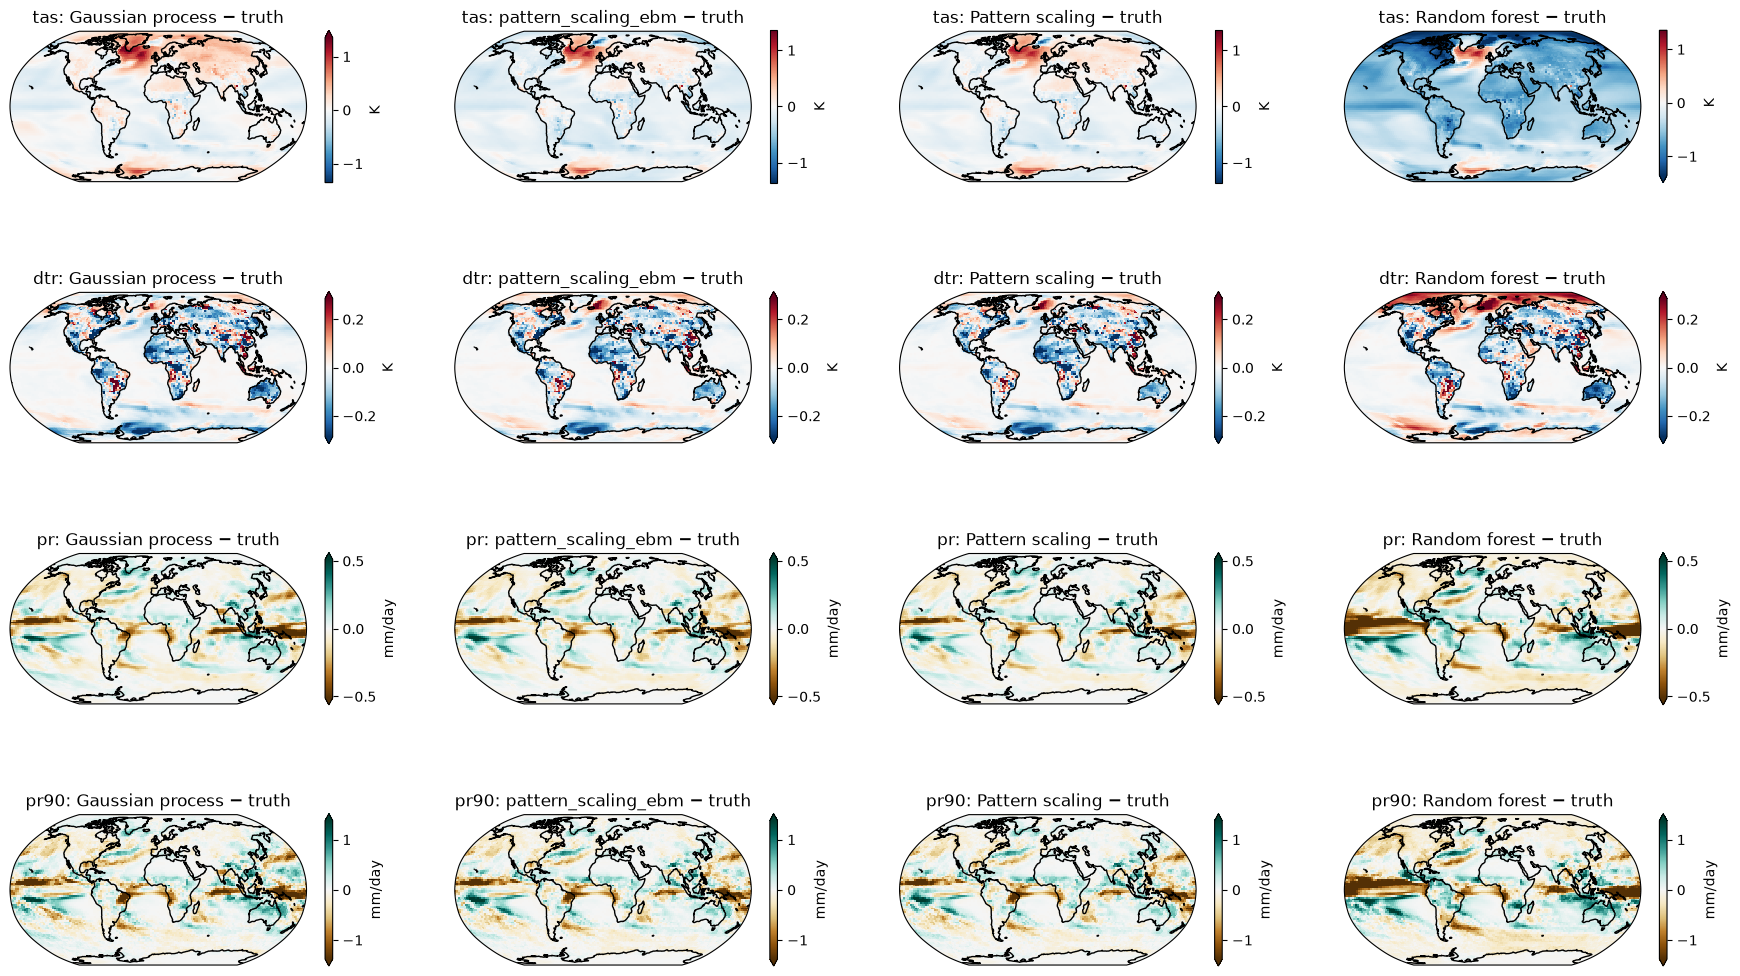

In [7]:
keys = list(preds)
fig, axes = plt.subplots(len(TARGETS), len(keys), figsize=(5.5 * len(keys), 13),
                         subplot_kw={"projection": ccrs.Robinson()}, squeeze=False)
for row, var in enumerate(TARGETS):
    name, unit, cmap = STYLE[var]
    t = truth[var].sel(time=PERIOD).mean("time")
    diffs = {k: preds[k][var].sel(time=PERIOD).mean("time") - t for k in keys}
    lim = max(float(np.nanpercentile(np.abs(d), 98)) for d in diffs.values())
    for ax, k in zip(axes[row], keys):
        diffs[k].plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=-lim, vmax=lim,
                      cbar_kwargs={"label": unit, "shrink": 0.7})
        ax.coastlines()
        ax.set_title(f"{name}: {MODELS.get(k, (k,))[0]} − truth")
fig.savefig(f"{FIGS}/week3_difference_maps.png", dpi=150, bbox_inches="tight")

## Global-mean trajectories

What the global NRMSE measures: each model's yearly global mean against the `ssp245` members and their mean.
The spread of the gray member lines is internal variability.

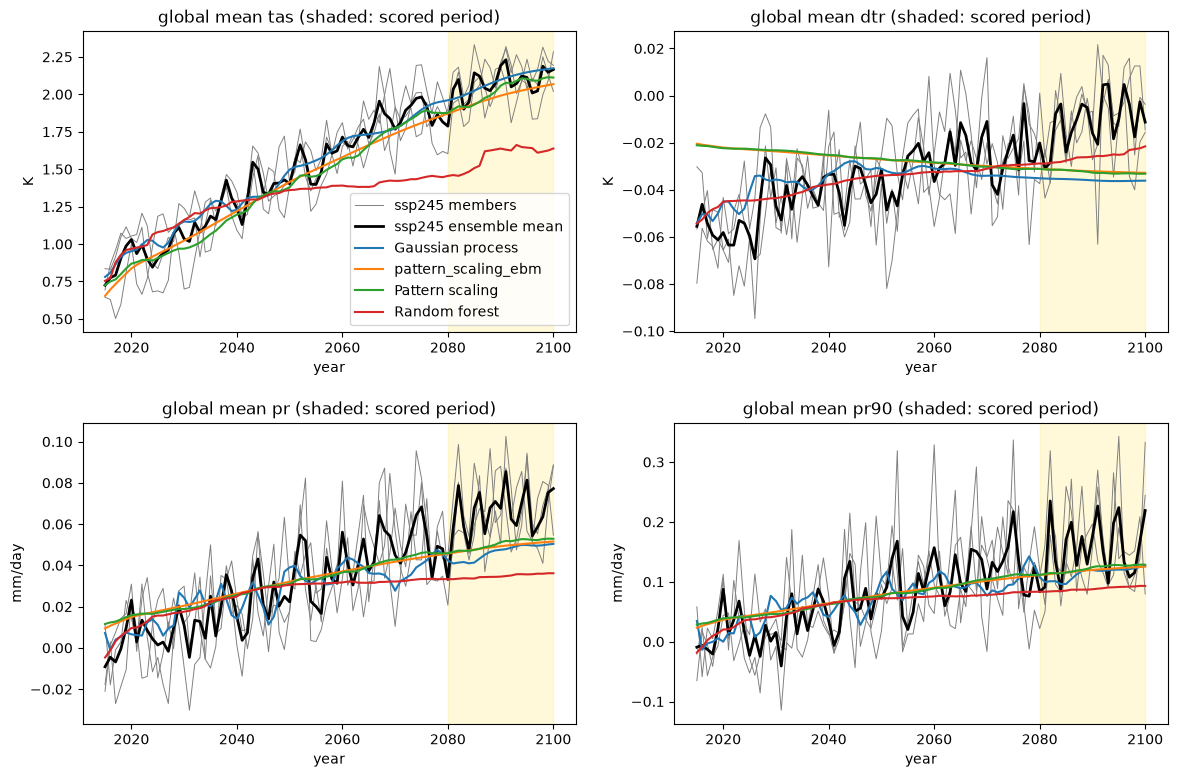

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"hspace": 0.3})
for ax, var in zip(axes.flat, TARGETS):
    name, unit, _ = STYLE[var]
    for i, m in enumerate(members.member.values):
        ax.plot(truth.time, global_mean(members[var].sel(member=m)), color="gray", lw=0.7,
                label="ssp245 members" if i == 0 else None)
    ax.plot(truth.time, global_mean(truth[var]), color="black", lw=2, label="ssp245 ensemble mean")
    for k, ds in preds.items():
        ax.plot(ds.time, global_mean(ds[var]), label=MODELS.get(k, (k,))[0])
    ax.axvspan(PERIOD.start, PERIOD.stop, color="gold", alpha=0.15)
    ax.set_title(f"global mean {name} (shaded: scored period)")
    ax.set_xlabel("year")
    ax.set_ylabel(unit)
axes[0, 0].legend()
fig.savefig(f"{FIGS}/week3_global_means.png", dpi=150, bbox_inches="tight")

## Notes for the write-up

- For each model and target: reproduced or not, and the most likely cause (Question 1).
- Which models beat pattern scaling, the reference point (Task 1).
- Which target is hardest, and why (Question 2).
- How our errors compare with the variability floor (Question 3).